# 02 · Naive Bayes Is Counting

There is no gradient descent here, no tuning loop, no optimisation of any kind.
"Training" a Naive Bayes model is **counting**: per-class means and variances for
continuous features, or word frequencies for counts. A single pass over the data and you
are done — which is why it is so fast and so data-efficient.

The one catch is a word (or feature value) never seen in a class: its probability is zero,
and a single zero annihilates the whole prediction. **Smoothing** is the fix.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from src import artifacts
from src.datasets import synthetic
from src.models import GaussianNB, MultinomialNB
from src.visualisation import plot_decision_boundary

np.set_printoptions(precision=3, suppress=True)

## 1. Gaussian Naive Bayes: the model *is* the summary statistics

For continuous features, each feature is modelled per class as a bell curve. "Fitting" is
just computing the mean and variance of each feature within each class. Those few numbers
**are** the entire trained model.

In [2]:
X, y = synthetic.make_correlated_data(
    n_samples=400, n_features=2, correlation=0.0, class_sep=2.0, seed=0
)
gnb = GaussianNB().fit(X, y)

print("Per-class feature means (theta_):\n", gnb.theta_)
print("\nPer-class feature variances (var_):\n", gnb.var_)
print("\nClass priors:", gnb.class_prior_)

artifacts.save_json(
    {
        "feature": "2D Gaussian synthetic",
        "class_means": gnb.theta_.tolist(),
        "class_variances": gnb.var_.tolist(),
        "class_priors": gnb.class_prior_.tolist(),
        "note": "These numbers are the whole model. Training only estimated them.",
    },
    "02_gaussian_parameters",
)

Per-class feature means (theta_):
 [[-0.982 -0.999]
 [ 0.973  0.949]]

Per-class feature variances (var_):
 [[0.997 0.978]
 [0.996 0.944]]

Class priors: [0.448 0.552]


PosixPath('/workspaces/naive_bayes_101/outputs/data/02_gaussian_parameters.json')

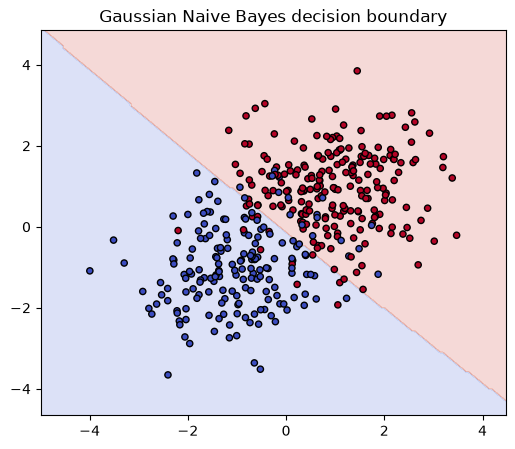

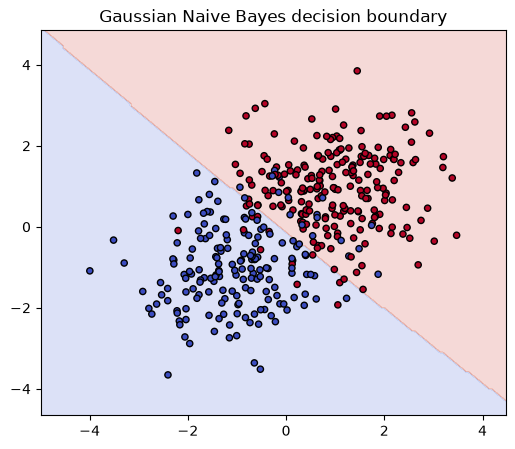

In [3]:
# The decision boundary those statistics imply, drawn in 2-D.
fig = plot_decision_boundary(gnb, X, y)
artifacts.save_fig(fig, "02_gaussian_decision_boundary")
fig

## 2. Multinomial Naive Bayes: the model *is* the word counts

For count features the story is even plainer. `feature_count_` is literally the summed word
counts per class — the trained model is a frequency table.

In [4]:
vocab = ["free", "money", "friend", "meeting"]
docs = np.array(
    [
        [3.0, 2.0, 0.0, 0.0],  # spam
        [4.0, 1.0, 1.0, 0.0],  # spam
        [0.0, 0.0, 2.0, 3.0],  # ham
        [1.0, 0.0, 1.0, 2.0],  # ham
    ]
)
labels = np.array([1, 1, 0, 0])
mnb = MultinomialNB(alpha=1.0).fit(docs, labels)

for cls, idx in [("ham", 0), ("spam", 1)]:
    row = int(np.where(mnb.classes_ == idx)[0][0])
    print(f"{cls:>4} word counts:", dict(zip(vocab, mnb.feature_count_[row])))

artifacts.save_json(
    {
        "vocabulary": vocab,
        "spam_counts": dict(zip(vocab, mnb.feature_count_[int(np.where(mnb.classes_ == 1)[0][0])].tolist())),
        "ham_counts": dict(zip(vocab, mnb.feature_count_[int(np.where(mnb.classes_ == 0)[0][0])].tolist())),
    },
    "02_multinomial_counts",
)

 ham word counts: {'free': np.float64(1.0), 'money': np.float64(0.0), 'friend': np.float64(3.0), 'meeting': np.float64(5.0)}
spam word counts: {'free': np.float64(7.0), 'money': np.float64(3.0), 'friend': np.float64(1.0), 'meeting': np.float64(0.0)}


PosixPath('/workspaces/naive_bayes_101/outputs/data/02_multinomial_counts.json')

## 3. One unseen word breaks everything — unless you smooth

Suppose a word never appeared in a class during training. Its probability is exactly 0, so
the product (a sum of logs) collapses to $-\infty$: the class is annihilated no matter what
the other words say. Add-one (Laplace) smoothing adds a pseudo-count so no probability is
ever zero.

In [5]:
# Word 1 ("surprise") never occurs in class 0's training data.
X_train = np.array([[1.0, 0.0], [2.0, 0.0], [0.0, 1.0], [0.0, 2.0]])
y_train = np.array([0, 0, 1, 1])
doc = np.array([[1.0, 1.0]])  # contains the word class 0 never saw

unsmoothed = MultinomialNB(alpha=0.0).fit(X_train, y_train)
smoothed = MultinomialNB(alpha=1.0).fit(X_train, y_train)

log_prob_unseen = unsmoothed.feature_log_prob_[0, 1]
jll_unsmoothed = unsmoothed._joint_log_likelihood(doc)[0]
print(f"Unsmoothed  log P(word1 | class0) = {log_prob_unseen}  (annihilates class 0)")
print(f"Unsmoothed  joint log-likelihood  = {jll_unsmoothed}")
print(f"Smoothed    P(class | doc)        = {smoothed.predict_proba(doc)[0]}")

artifacts.save_json(
    {
        "unseen_word_log_prob_unsmoothed": float(log_prob_unseen),
        "joint_log_likelihood_unsmoothed": jll_unsmoothed.tolist(),
        "class0_annihilated": bool(np.isneginf(jll_unsmoothed[0])),
        "smoothed_posterior": smoothed.predict_proba(doc)[0].tolist(),
    },
    "02_smoothing_rescue",
)

Unsmoothed  log P(word1 | class0) = -inf  (annihilates class 0)
Unsmoothed  joint log-likelihood  = [-inf -inf]
Smoothed    P(class | doc)        = [0.5 0.5]


PosixPath('/workspaces/naive_bayes_101/outputs/data/02_smoothing_rescue.json')

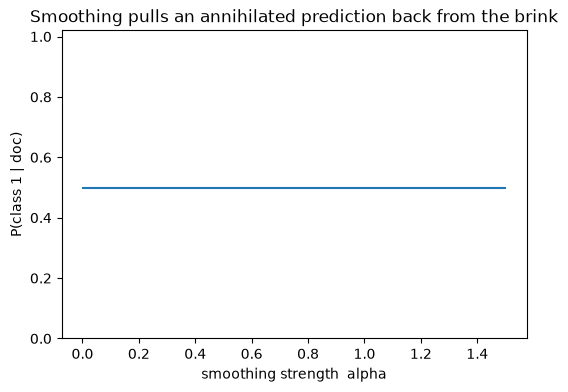

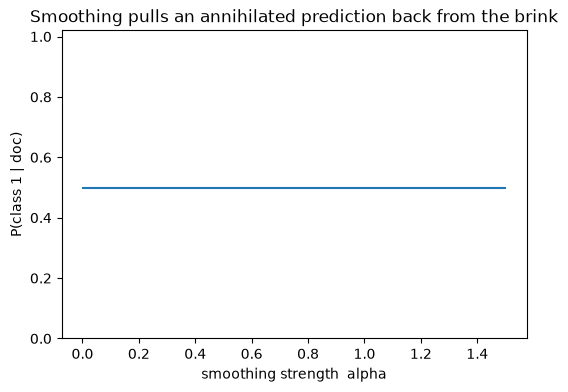

In [6]:
# How the posterior moves as smoothing strength alpha increases.
spam_index = int(np.where(smoothed.classes_ == 1)[0][0])
alphas = np.linspace(0.001, 1.5, 60)
posteriors = [
    MultinomialNB(alpha=a).fit(X_train, y_train).predict_proba(doc)[0][spam_index]
    for a in alphas
]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(alphas, posteriors, color="tab:blue")
ax.set_xlabel("smoothing strength  alpha")
ax.set_ylabel("P(class 1 | doc)")
ax.set_title("Smoothing pulls an annihilated prediction back from the brink")
ax.set_ylim(0, 1.02)
artifacts.save_fig(fig, "02_posterior_vs_alpha")
fig

## 4. "Training" is a single pass

To make the point literal: fitting is so cheap it is essentially the cost of reading the
data once.

In [7]:
X_big, y_big = synthetic.make_count_data(n_samples=20000, n_features=200, seed=1)
start = time.perf_counter()
MultinomialNB(alpha=1.0).fit(X_big, y_big)
elapsed = time.perf_counter() - start
print(f"Trained Multinomial NB on {X_big.shape[0]} x {X_big.shape[1]} counts in {elapsed * 1000:.1f} ms")

artifacts.save_json(
    {"n_samples": int(X_big.shape[0]), "n_features": int(X_big.shape[1]),
     "train_milliseconds": elapsed * 1000.0},
    "02_training_time",
)

Trained Multinomial NB on 20000 x 200 counts in 14.9 ms


PosixPath('/workspaces/naive_bayes_101/outputs/data/02_training_time.json')

## Takeaway

The entire model is tallies: means and variances, or word counts — estimated in one pass,
with one safety fix (smoothing) so a single unseen feature cannot zero out a prediction.

Next (**notebook 03**): point this counting machine at real email and watch it match
logistic regression while training far faster.